# F1 Podium Prediction: Milestone 1

## Section 1: Data cleaning and EDA

### 1.1 Load the data

We load all 14 tables into a dictionary called `raw`. The CSV files are never changed: we clean copies later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']

raw = {}
for t in TABLES:
    raw[t] = pd.read_csv(f'{DATA_DIR}/{t}.csv')

for t in TABLES:
    print(t, raw[t].shape)

circuits (77, 9)
constructors (212, 5)
constructor_results (12625, 5)
constructor_standings (13391, 7)
drivers (861, 9)
driver_standings (34863, 7)
races (1125, 18)
results (26759, 18)
qualifying (10494, 9)
lap_times (589081, 6)
pit_stops (11371, 7)
sprint_results (360, 16)
seasons (75, 2)
status (139, 2)


### 1.2 EDA before cleaning: missing values

This dataset does not leave missing cells empty. It writes the text `\N` instead, so pandas does not see them as missing.
We count the `\N` values in every table.

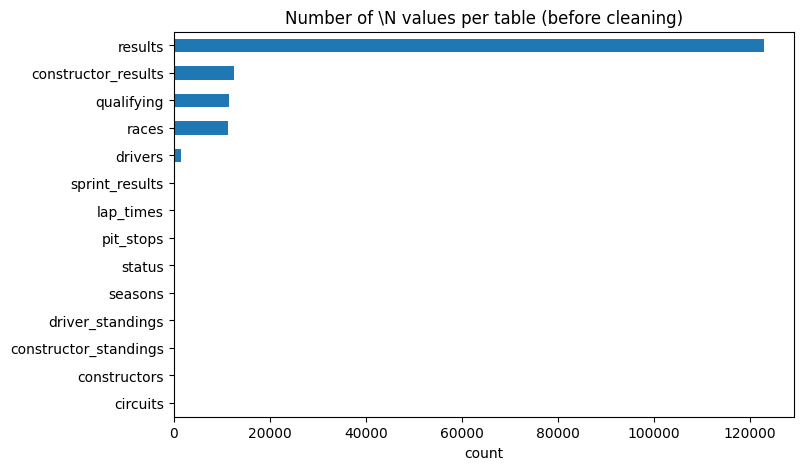

In [2]:
missing_before = {}
for t in TABLES:
    missing_before[t] = (raw[t] == '\\N').sum().sum()

pd.Series(missing_before).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Number of \\N values per table (before cleaning)')
plt.xlabel('count')
plt.show()

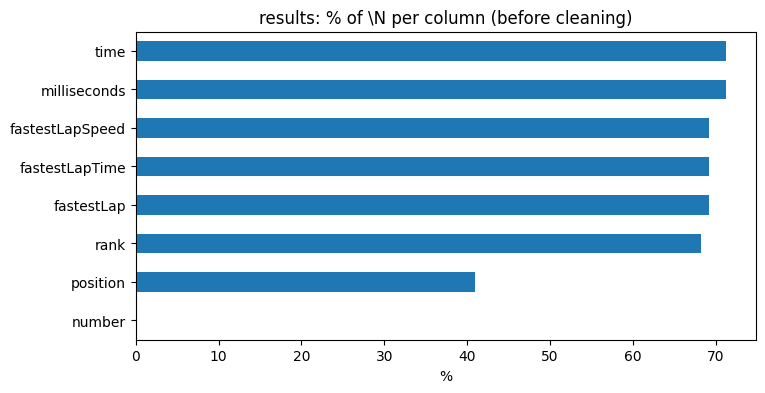

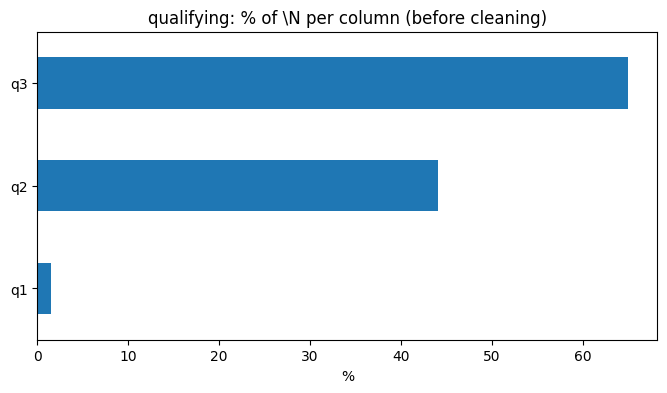

In [3]:
# Which columns of the two most important tables have missing values?
for t in ['results', 'qualifying']:
    pct = (raw[t] == '\\N').mean() * 100
    pct[pct > 0].sort_values().plot(kind='barh', figsize=(8, 4))
    plt.title(f'{t}: % of \\N per column (before cleaning)')
    plt.xlabel('%')
    plt.show()

### 1.3 Clean the missing values and fix the types

1. Replace every `\N` with `NaN`, the real "missing" value in pandas.
2. Turn a column into numbers if all its values are numbers. Columns like this were stored as text only because of the `\N`.
3. Turn date columns into real dates.
4. Turn qualifying lap times like `1:23.456` into seconds (83.456), so they can be compared and used as features.

In [4]:
def to_numbers(df):
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors='coerce')
        if converted.notna().sum() == df[col].notna().sum():   # every value was a number
            df[col] = converted
    return df

def lap_time_to_seconds(text):
    if pd.isna(text):
        return np.nan
    minutes, seconds = text.split(':')
    return float(minutes) * 60 + float(seconds)

clean = {}
for t in TABLES:
    clean[t] = to_numbers(raw[t].replace('\\N', np.nan))

clean['races']['date'] = pd.to_datetime(clean['races']['date'])
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'])
for col in ['q1', 'q2', 'q3']:
    clean['qualifying'][col] = clean['qualifying'][col].map(lap_time_to_seconds)

clean['qualifying'][['q1', 'q2', 'q3']].describe()

,q1,q2,q3
count,10338.000000,5847.000000,3629.000000
mean,88.531251,87.770120,87.405623
std,15.392958,12.110624,12.260018
min,53.904000,53.647000,53.377000
25%,78.773500,77.942000,77.238000
50%,87.141000,87.125000,87.039000
75%,95.909500,95.956000,95.626000
max,1002.640000,132.470000,129.776000


### 1.4 Check the keys

* **Primary key:** the column that identifies each row. It must be unique and never missing.
* **Foreign key:** a column that points to a row in another table (for example `results.driverId` points to `drivers`).
  Every value must exist in that other table, otherwise joins lose rows.

In [5]:
primary_keys = {
    'circuits': 'circuitId', 'constructors': 'constructorId', 'drivers': 'driverId', 'races': 'raceId',
    'results': 'resultId', 'qualifying': 'qualifyId', 'status': 'statusId', 'seasons': 'year',
    'constructor_results': 'constructorResultsId', 'constructor_standings': 'constructorStandingsId',
    'driver_standings': 'driverStandingsId', 'sprint_results': 'resultId',
}
for t, key in primary_keys.items():
    unique = clean[t][key].is_unique
    no_missing = clean[t][key].notna().all()
    print(f'{t}.{key}: unique={unique}, no missing={no_missing}')

circuits.circuitId: unique=True, no missing=True
constructors.constructorId: unique=True, no missing=True
drivers.driverId: unique=True, no missing=True
races.raceId: unique=True, no missing=True
results.resultId: unique=True, no missing=True
qualifying.qualifyId: unique=True, no missing=True
status.statusId: unique=True, no missing=True
seasons.year: unique=True, no missing=True
constructor_results.constructorResultsId: unique=True, no missing=True
constructor_standings.constructorStandingsId: unique=True, no missing=True
driver_standings.driverStandingsId: unique=True, no missing=True
sprint_results.resultId: unique=True, no missing=True


In [6]:
foreign_keys = [  # (table, column, table it points to, key there)
    ('races', 'circuitId', 'circuits', 'circuitId'),
    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),
    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
]
for table, col, parent, parent_key in foreign_keys:
    missing = ~clean[table][col].isin(clean[parent][parent_key])
    print(f'{table}.{col} -> {parent}: {missing.sum()} values not found')

races.circuitId -> circuits: 0 values not found
results.raceId -> races: 0 values not found
results.driverId -> drivers: 0 values not found
results.constructorId -> constructors: 0 values not found
results.statusId -> status: 0 values not found
qualifying.raceId -> races: 0 values not found
qualifying.driverId -> drivers: 0 values not found
driver_standings.raceId -> races: 0 values not found
driver_standings.driverId -> drivers: 0 values not found
constructor_standings.constructorId -> constructors: 0 values not found


### 1.5 One row per driver per race

Each row of our model is one prediction: "will this driver finish on the podium in this race?"
So a driver can only appear once per race. In the 1950s, drivers sometimes drove two cars in the same race
(shared drives), which gives them two rows.

In [7]:
results = clean['results']
dup = results[results.duplicated(['raceId', 'driverId'], keep=False)]
print('Rows that are duplicates:', len(dup))
print('Years:', sorted(dup.merge(clean['races'], on='raceId')['year'].unique().tolist()))
dup[['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder']]

Rows that are duplicates: 176
Years: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


,raceId,driverId,constructorId,grid,positionOrder
13188,540,229,54,0,26
13191,540,229,57,0,29
17362,717,373,172,1,7
17740,733,465,172,0,22
17743,733,465,97,0,25
...,...,...,...,...,...
20293,770,479,118,10,14
20294,774,566,105,11,4
20295,746,475,170,8,3
24297,745,418,172,15,11


**Our rule: keep the row of the car the driver started the race in** (the row with a grid position above 0).
If more than one row qualifies, we keep the first one listed.

Why: our features (grid, qualifying) must describe the car the driver actually started in, because that is what is
known before the race. Choosing the row with the best finishing position instead would use the race result, which is
not known before the race.

In [8]:
results = results.assign(no_start=(results['grid'] == 0))
results = results.sort_values(['no_start', 'resultId'])
results = results.drop_duplicates(['raceId', 'driverId'])
clean['results'] = results.drop(columns='no_start').sort_values('resultId')

print('Rows before:', len(raw['results']), '| rows after:', len(clean['results']))
print('Duplicates left:', clean['results'].duplicated(['raceId', 'driverId']).sum())

Rows before: 26759 | rows after: 26668
Duplicates left: 0


### 1.6 EDA after cleaning

We add `podium` (finished 1st, 2nd or 3rd) only to explore the data here.

In [9]:
data = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
data['podium'] = data['positionOrder'] <= 3

summary = pd.DataFrame({
    'rows before': [len(raw[t]) for t in TABLES],
    'rows after': [len(clean[t]) for t in TABLES],
    '\\N before': [missing_before[t] for t in TABLES],
    'NaN after': [clean[t].isna().sum().sum() for t in TABLES],
    'number columns before': [raw[t].select_dtypes('number').shape[1] for t in TABLES],
    'number columns after': [clean[t].select_dtypes('number').shape[1] for t in TABLES],
}, index=TABLES)
summary

,rows before,rows after,\N before,NaN after,number columns before,number columns after
circuits,77,77,0,0,4,4
constructors,212,212,0,0,1,1
constructor_results,12625,12625,12608,12608,4,4
constructor_standings,13391,13391,0,0,6,6
drivers,861,861,1559,1559,1,2
driver_standings,34863,34863,0,0,6,6
races,1125,1125,11349,11349,4,4
results,26759,26668,122887,122339,9,15
qualifying,10494,10494,11600,11668,6,9
lap_times,589081,589081,0,0,5,5


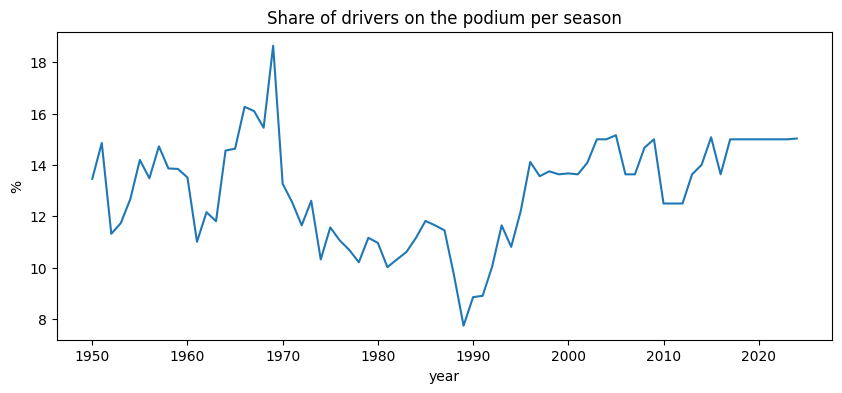

Overall: 12.7% of rows are podiums, so the classes are unbalanced.


In [10]:
(data.groupby('year')['podium'].mean() * 100).plot(figsize=(10, 4))
plt.title('Share of drivers on the podium per season')
plt.ylabel('%')
plt.show()
print(f'Overall: {data["podium"].mean():.1%} of rows are podiums, so the classes are unbalanced.')

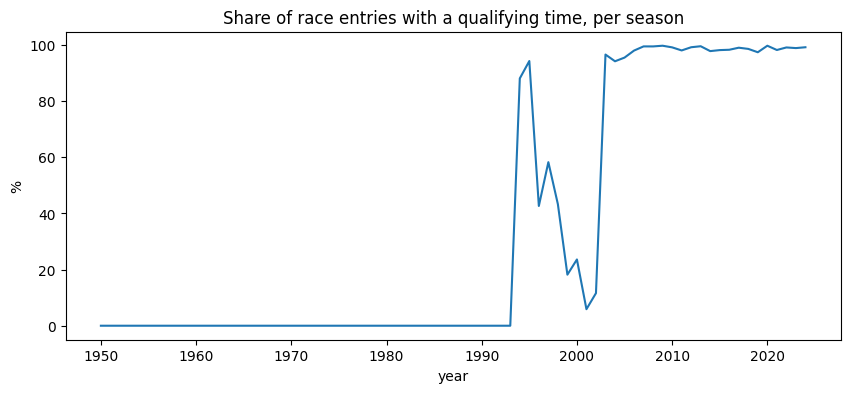

In [11]:
has_quali = data.merge(clean['qualifying'][['raceId', 'driverId', 'q1']], on=['raceId', 'driverId'], how='left')
(has_quali.groupby('year')['q1'].apply(lambda s: s.notna().mean()) * 100).plot(figsize=(10, 4))
plt.title('Share of race entries with a qualifying time, per season')
plt.ylabel('%')
plt.show()

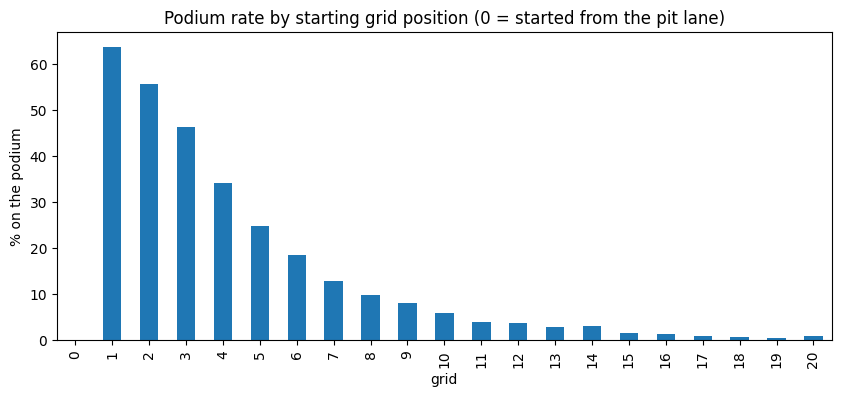

In [12]:
(data[data['grid'] <= 20].groupby('grid')['podium'].mean() * 100).plot(kind='bar', figsize=(10, 4))
plt.title('Podium rate by starting grid position (0 = started from the pit lane)')
plt.ylabel('% on the podium')
plt.show()

## Section 2: Data-engineering questions

Each question joins several tables, ends with one plot, and has a short answer.
None of this is used as a model feature: these are questions about the history of F1.

### 2.1 Q1: Which circuits turn a front-row start into a podium most often? Did that change after 2014?

* **Front-row start** = starting 1st or 2nd. **Conversion** = share of front-row starters who finish in the top 3.
* **Tables:** `results` -> `races` -> `circuits`, and `results` -> `qualifying`.
* **Grain:** one row per (raceId, driverId).
* **Qualifying is not grid.** Qualifying is where the driver earned their spot, grid is where the car really started
  (after penalties). We use the grid as the main answer and repeat it with qualifying as a check.
* **Missing data:** qualifying data only exists for later seasons, so we keep only rows that have it.
  That way both definitions are measured on the same rows.
* **Cutoff:** grid and qualifying are known before the race. `positionOrder` is only the outcome we count.

In [13]:
q = clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
df = (clean['results'][['raceId', 'driverId', 'grid', 'positionOrder']]
      .merge(clean['races'][['raceId', 'year', 'circuitId']], on='raceId')
      .merge(clean['circuits'][['circuitId', 'name']].rename(columns={'name': 'circuit'}), on='circuitId')
      .merge(q, on=['raceId', 'driverId'], how='inner', validate='m:1'))   # inner: only rows with qualifying data

df['podium'] = df['positionOrder'] <= 3
df['era'] = np.where(df['year'] < 2014, 'before 2014', '2014+')
df['front_grid'] = df['grid'].between(1, 2)      # where the car really started (grid 0 = pit lane, not front row)
df['front_quali'] = df['quali_pos'] <= 2         # where the driver qualified

print('First season with qualifying data:', df['year'].min())
print('Rows where qualifying and grid disagree about the front row:', (df['front_grid'] != df['front_quali']).sum())

First season with qualifying data: 1994
Rows where qualifying and grid disagree about the front row: 74


In [14]:
def conversion(flag, min_starts=12):
    # podium rate of front-row starters, per circuit and era
    g = df[df[flag]].groupby(['circuit', 'era'])['podium'].agg(['size', 'mean']).reset_index()
    g = g[g['size'] >= min_starts]                                            # too few starts = noise
    return g.pivot(index='circuit', columns='era', values='mean').dropna()   # keep circuits seen in both eras

by_grid = conversion('front_grid')
by_quali = conversion('front_quali')

rho = by_grid['before 2014'].corr(by_grid['2014+'], method='spearman')
a, b = by_grid.align(by_quali, join='inner')
print(f'{len(by_grid)} circuits | ranking agreement before vs after 2014 (Spearman): {rho:.2f}')
print(f'Same ranking if front row is defined by qualifying instead of grid: {a.stack().corr(b.stack(), method="spearman"):.2f}')

13 circuits | ranking agreement before vs after 2014 (Spearman): 0.23
Same ranking if front row is defined by qualifying instead of grid: 0.88


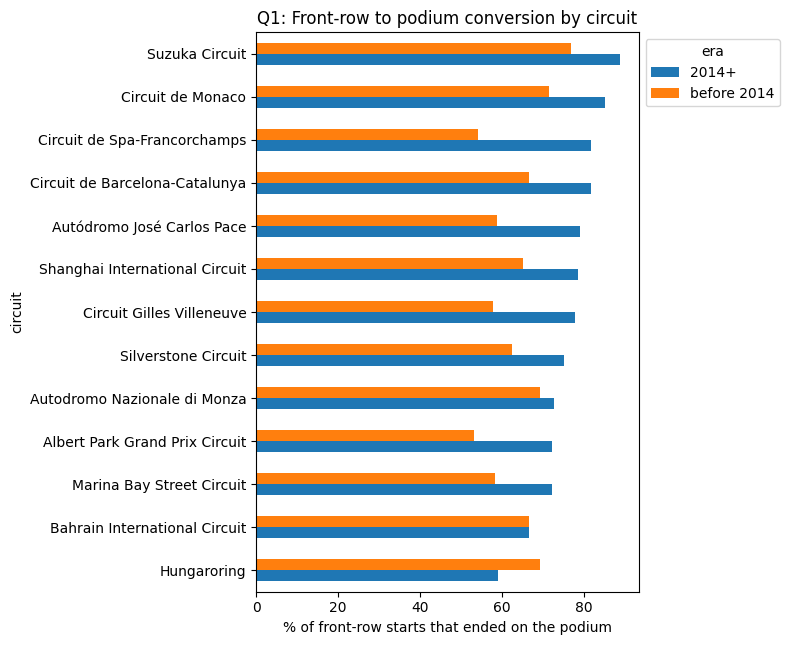

era,2014+,before 2014,change
circuit,,,
Suzuka Circuit,88.9,76.9,12.0
Circuit de Monaco,85.0,71.4,13.6
Circuit de Spa-Francorchamps,81.8,54.2,27.7
Circuit de Barcelona-Catalunya,81.8,66.7,15.2
Autódromo José Carlos Pace,78.9,58.8,20.1
Shanghai International Circuit,78.6,65.0,13.6
Circuit Gilles Villeneuve,77.8,57.7,20.1
Silverstone Circuit,75.0,62.5,12.5
Autodromo Nazionale di Monza,72.7,69.2,3.5


In [15]:
(by_grid.sort_values('2014+') * 100).plot(kind='barh', figsize=(8, 0.35 * len(by_grid) + 2))
plt.xlabel('% of front-row starts that ended on the podium')
plt.title('Q1: Front-row to podium conversion by circuit')
plt.legend(title='era', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

(by_grid.assign(change=by_grid['2014+'] - by_grid['before 2014'])
        .sort_values('2014+', ascending=False) * 100).round(1)

**Answer Q1:**
Starting on the front row became a much safer bet after 2014: conversion went up at 11 of the 13 circuits
(Bahrain stayed the same, only the Hungaroring went down).
Before 2014 the best circuits were Suzuka (77 %), Monaco (71 %), Monza and the Hungaroring (69 %).
From 2014 they were Suzuka (89 %), Monaco (85 %), Spa and Barcelona (82 %).
Suzuka and Monaco stay on top, but the rest of the ranking changed a lot: the rank agreement between the two eras
is only 0.23 (1 = same order). Spa moved up the most (+28 points), the Hungaroring went down (-10 points).
Using qualifying instead of grid gives almost the same picture (agreement 0.88), even though the two definitions
disagree in 74 rows because of grid penalties.

*Limit:* only 13 circuits have enough front-row starts in both eras (1994-2013 and 2014-2024), and each rate is based on
a few dozen starts, so a change at one single circuit can be noise.

### 2.2 Q2: Do drivers podium more often at home, for the same starting position?

* **Home race** = the driver's nationality matches the circuit's country (e.g. "British" driver at a "UK" circuit).
  We write this mapping by hand below.
* **Tables:** `results` -> `drivers` (nationality), and `results` -> `races` -> `circuits` (country).
* **Grain:** one row per (raceId, driverId). Only drivers who started from a grid slot (`grid >= 1`).
* **Indianapolis 500 removed:** it was mostly American drivers who never raced elsewhere, so it would fake a home effect.
* **Same starting position:** home drivers might just qualify better. So we split drivers into grid bands
  (1-3, 4-6, 7-10, 11+) and compare home vs away *inside each band*.
* **Cutoff:** nationality, circuit and grid are all known before the race.

In [16]:
NATIONALITY_TO_COUNTRY = {
    'British': 'UK', 'German': 'Germany', 'East German': 'Germany', 'Italian': 'Italy', 'French': 'France',
    'Spanish': 'Spain', 'Argentinian': 'Argentina', 'Brazilian': 'Brazil', 'American': 'USA', 'Australian': 'Australia', 'Austrian': 'Austria',
    'Belgian': 'Belgium', 'Dutch': 'Netherlands', 'Canadian': 'Canada', 'Mexican': 'Mexico', 'Japanese': 'Japan',
    'Hungarian': 'Hungary', 'Monegasque': 'Monaco', 'Portuguese': 'Portugal', 'Russian': 'Russia',
    'Swiss': 'Switzerland', 'Swedish': 'Sweden', 'Argentine': 'Argentina', 'South African': 'South Africa',
    'Chinese': 'China', 'Malaysian': 'Malaysia', 'Indian': 'India', 'Moroccan': 'Morocco', 'Turkish': 'Turkey',
}

home = (clean['results'][['raceId', 'driverId', 'grid', 'positionOrder']]
        .merge(clean['races'][['raceId', 'year', 'name', 'circuitId']], on='raceId')
        .merge(clean['circuits'][['circuitId', 'country']], on='circuitId')
        .merge(clean['drivers'][['driverId', 'nationality']], on='driverId'))
home = home[(home['grid'] >= 1) & (home['name'] != 'Indianapolis 500')].copy()

home['nationality'] = home['nationality'].str.strip()           # the data has 'Argentinian ' with a space
home['country'] = home['country'].replace({'United States': 'USA'})
home['home_race'] = home['nationality'].map(NATIONALITY_TO_COUNTRY) == home['country']
home['podium'] = home['positionOrder'] <= 3

# check the hand-made mapping: every country we map to must really exist as a circuit country
print('Mapped countries with no circuit (spelling check, should be empty):',
      sorted(set(NATIONALITY_TO_COUNTRY.values()) - set(home['country'])))
print('Nationalities with no home circuit:', sorted(set(home['nationality']) - set(NATIONALITY_TO_COUNTRY)))
print(f'Rows: {len(home)} | home-race rows: {home["home_race"].sum()}')

Mapped countries with no circuit (spelling check, should be empty): []
Nationalities with no home circuit: ['American-Italian', 'Argentine-Italian', 'Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Rows: 24652 | home-race rows: 1942


In [17]:
home['grid_band'] = pd.cut(home['grid'], bins=[0, 3, 6, 10, 99], labels=['1-3', '4-6', '7-10', '11+'])

q2 = home.groupby(['grid_band', 'home_race'], observed=True)['podium'].agg(['size', 'mean']).unstack()
q2.columns = ['rows away', 'rows home', 'podium % away', 'podium % home']
q2[['podium % away', 'podium % home']] *= 100
q2['difference'] = q2['podium % home'] - q2['podium % away']

raw_diff = (home.loc[home['home_race'], 'podium'].mean() - home.loc[~home['home_race'], 'podium'].mean()) * 100
bands = q2.dropna()
fair_diff = np.average(bands['difference'], weights=bands['rows home'])   # same grid band, weighted by home rows
print(f'Home minus away, ignoring the grid:          {raw_diff:+.1f} percentage points')
print(f'Home minus away, inside the same grid band:  {fair_diff:+.1f} percentage points')
q2.round(1)

Home minus away, ignoring the grid:          -2.1 percentage points
Home minus away, inside the same grid band:  -0.6 percentage points


,rows away,rows home,podium % away,podium % home,difference
grid_band,,,,,
1-3,3111,231,55.4,55.8,0.5
4-6,3117,226,26.0,26.5,0.5
7-10,4118,336,9.2,7.1,-2.1
11+,12364,1149,1.7,1.0,-0.6


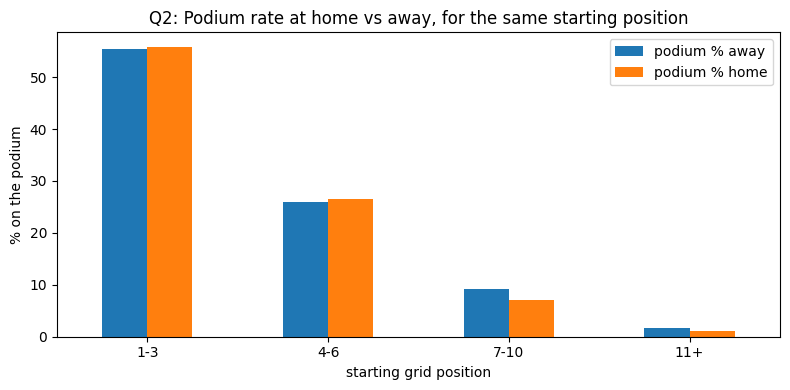

In [18]:
q2[['podium % away', 'podium % home']].plot(kind='bar', figsize=(8, 4), rot=0)
plt.xlabel('starting grid position')
plt.ylabel('% on the podium')
plt.title('Q2: Podium rate at home vs away, for the same starting position')
plt.tight_layout()
plt.show()

**Answer Q2:**
No, there is no real home advantage. Ignoring the grid, home drivers even podium 2.1 percentage points *less* often.
Comparing drivers who started in the same grid band, the difference is only -0.6 points, and in every band the
home and away rates are within about 2 points of each other (see the chart). Where you start matters far more than
where you race.

*Limits:* nationality is not always the same as "home", drivers with two nationalities (e.g. American-Italian) and
countries without a race have no home race, and there are only about 230 home rows in each of the front bands.

### 2.3 Q3: Which constructors have the highest mechanical-retirement rate, 2014-2021 vs 2022-2024?

* **Mechanical retirement** = a race start that ended because a part of the car failed (engine, gearbox, brakes...).
  Crashes, driver errors, disqualifications and unknown reasons do **not** count.
* `status.csv` has over 100 reasons. We group them with a list of keywords below, and print the full mapping
  so anyone can check it.
* **Tables:** `results` -> `status`, `results` -> `races` (year), `results` -> `constructors` (team name).
* **Rate** = mechanical retirements / race starts. Drivers who never started (`positionText` F or W) are removed.
  Teams with fewer than 40 starts in an era are left out.
* **Cutoff:** status is post-race information. That is fine here, because this is a question about history,
  not a model feature.

In [19]:
MECHANICAL_WORDS = [
    'engine', 'gearbox', 'transmission', 'clutch', 'hydraulic', 'electr', 'brake', 'suspension', 'differential',
    'overheating', 'mechanical', 'technical', 'driveshaft', 'halfshaft', 'drivetrain', 'pressure', 'leak', 'pump',
    'throttle', 'steering', 'track rod', 'exhaust', 'radiator', 'cooling', 'power unit', 'turbo', 'supercharger',
    'battery', 'alternator', 'wheel', 'axle', 'chassis', 'crankshaft', 'cv joint', 'spark', 'ignition',
    'fuel system', 'fuel line', 'oil line', 'pneumatic', 'vibration', 'power loss', 'launch control',
    'rear wing', 'undertray', 'heat shield',
]
NOT_MECHANICAL = ['damage', 'out of fuel', 'refuel', 'fuel rig']   # caused by a crash or the team, not a broken part


def status_group(status):
    s = status.lower()
    if s == 'finished' or s.startswith('+') or s == 'lapped':
        return 'finished'
    if any(w in s for w in NOT_MECHANICAL):
        return 'other retirement'
    if s == 'ers' or any(w in s for w in MECHANICAL_WORDS):
        return 'mechanical'
    return 'other retirement'          # crash, collision, spun off, disqualified, tyre/puncture, retired (unknown), ...


status_map = clean['status'].assign(group=clean['status']['status'].map(status_group))

q3 = (clean['results'][['raceId', 'constructorId', 'positionText', 'statusId']]
      .merge(clean['races'][['raceId', 'year']], on='raceId')
      .merge(status_map, on='statusId')
      .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId'))
q3 = q3[q3['year'].between(2014, 2024) & ~q3['positionText'].isin(['F', 'W']) & (q3['status'] != 'Withdrew')].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
q3['mechanical'] = q3['group'] == 'mechanical'

# the full mapping, for the statuses that appear in 2014-2024 (number of rows in brackets)
for group, part in q3.groupby('group'):
    counts = part['status'].value_counts()
    print(f'{group.upper()}: ' + ', '.join(f'{s} ({n})' for s, n in counts.items()) + '\n')

FINISHED: Finished (2403), +1 Lap (1178), +2 Laps (208), +3 Laps (24), +4 Laps (6), +8 Laps (2), +6 Laps (2), +5 Laps (1), +7 Laps (1)

MECHANICAL: Engine (79), Brakes (48), Gearbox (40), Power Unit (39), Suspension (25), Electrical (14), Hydraulics (14), Power loss (12), Wheel (11), Oil leak (10), Overheating (8), Mechanical (7), Water pressure (7), Turbo (6), Battery (5), Fuel pressure (5), Electronics (4), Water leak (4), ERS (4), Undertray (4), Exhaust (4), Wheel nut (3), Transmission (3), Rear wing (3), Radiator (3), Technical (2), Oil pressure (2), Throttle (2), Steering (2), Vibrations (2), Clutch (2), Drivetrain (1), Brake duct (1), Driveshaft (1), Spark plugs (1), Cooling system (1), Water pump (1), Fuel leak (1), Fuel pump (1), Differential (1)

OTHER RETIREMENT: Collision (150), Accident (85), Collision damage (59), Retired (49), Disqualified (11), Spun off (11), Puncture (7), Tyre (4), Front wing (3), Illness (2), Damage (2), Seat (1), Excluded (1), Out of fuel (1), Debris 

In [20]:
rates = q3.groupby(['constructor', 'era'])['mechanical'].agg(starts='size', rate='mean').reset_index()
rates = rates[rates['starts'] >= 40]
rates['rate'] *= 100
q3_table = rates.pivot(index='constructor', columns='era', values='rate').round(1)

print((q3.groupby('era')['mechanical'].mean() * 100).round(1).rename('all teams, % of starts'))
q3_table.sort_values('2022-2024', ascending=False)

era
2014-2021    9.4
2022-2024    5.8
Name: all teams, % of starts, dtype: float64


era,2014-2021,2022-2024
constructor,,
Alfa Romeo,4.2,12.5
Alpine F1 Team,9.1,10.4
AlphaTauri,9.1,8.0
Williams,7.5,6.0
Aston Martin,2.3,5.3
Ferrari,5.7,5.2
Mercedes,4.1,4.4
Haas F1 Team,9.6,4.4
RB F1 Team,NaN,4.2


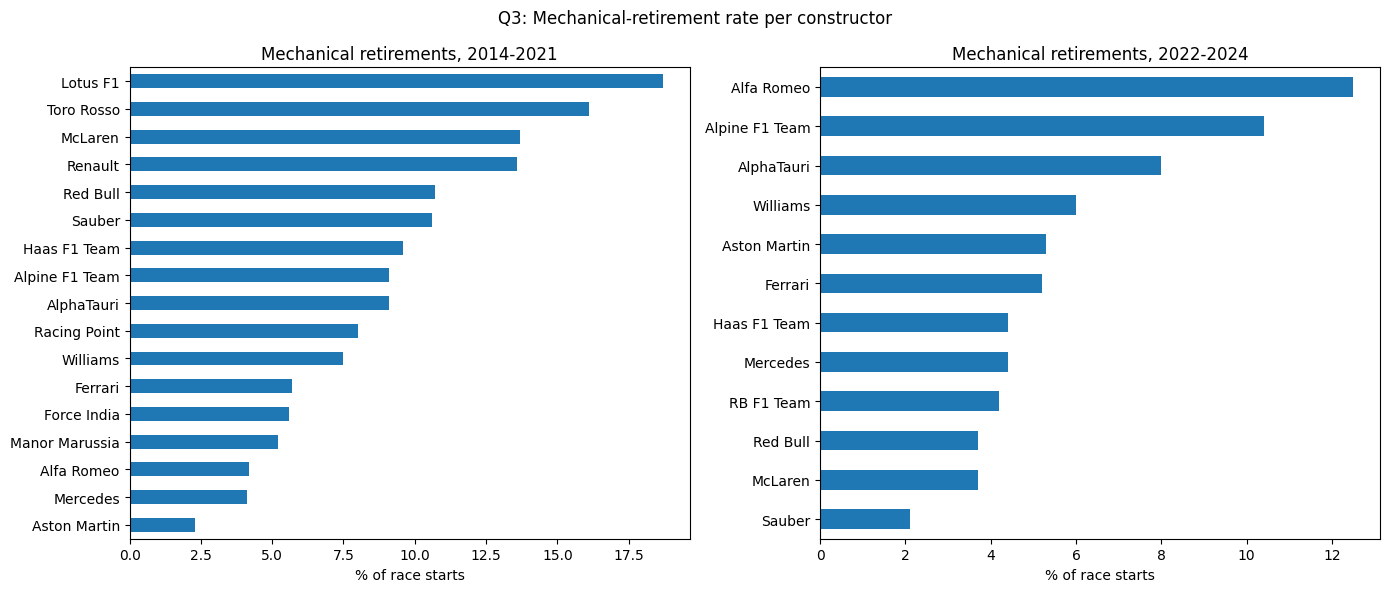

Highest in 2014-2021: Lotus F1 (18.7%), Toro Rosso (16.1%), McLaren (13.7%)
Highest in 2022-2024: Alfa Romeo (12.5%), Alpine F1 Team (10.4%), AlphaTauri (8.0%)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, era in zip(axes, ['2014-2021', '2022-2024']):
    q3_table[era].dropna().sort_values().plot(kind='barh', ax=ax)
    ax.set_title(f'Mechanical retirements, {era}')
    ax.set_xlabel('% of race starts')
    ax.set_ylabel('')
plt.suptitle('Q3: Mechanical-retirement rate per constructor')
plt.tight_layout()
plt.show()

for era in ['2014-2021', '2022-2024']:
    top = q3_table[era].dropna().sort_values(ascending=False).head(3)
    print(f'Highest in {era}: ' + ', '.join(f'{c} ({r:.1f}%)' for c, r in top.items()))

**Answer Q3:**
In 2014-2021 the highest mechanical-retirement rates were Lotus F1 (18.7 %), Toro Rosso (16.1 %) and McLaren (13.7 %),
just ahead of Renault (13.6 %). In 2022-2024 they were Alfa Romeo (12.5 %), Alpine (10.4 %) and AlphaTauri (8.0 %).
Over all teams the rate fell from 9.4 % to 5.8 % of starts, so cars became more reliable.
The biggest improvements were McLaren (13.7 % -> 3.7 %) and Red Bull (10.7 % -> 3.7 %).
Alfa Romeo went the other way (4.2 % -> 12.5 %).

*Limits:* teams that were renamed count as separate teams (e.g. Toro Rosso -> AlphaTauri -> RB,
Force India -> Racing Point -> Aston Martin). "Retired" with no reason is counted as not mechanical, and
tyre failures/punctures are counted as not mechanical because they are usually caused by debris or contact.

## Section 3: Modeling table and features

Goal: one table with **one row per (raceId, driverId)**, the target `podium` (`positionOrder <= 3`), and features that
are all known **after the starting grid is fixed and before the race starts**.

The rule every feature follows. A feature may only use:
* the grid and qualifying of **this** race (fixed before the start), or
* results and standings of races that finished **before** this race.

Everything this race produces (`positionOrder`, `points`, `status`, `laps`, times, pit stops, lap times, and the
standings *after* this race) is only used to build the target, never as a feature.

### 3.1 Which rows go into the table

1. **Drop the Indianapolis 500 (1950 to 1960).** It counted for the championship, but almost no F1 regulars entered
   and its drivers rarely raced anywhere else, so their "form" and "standings" would be meaningless. We filter by the
   race name, not the circuit, because the US Grand Prix of 2000 to 2007 was held on the same circuit and is a normal F1 race.
2. **Drop entries that never took the start:** `positionText` `F` (failed to qualify) and `W` (withdrawn). At our
   cutoff the grid is already fixed, so we already know these drivers are not racing; there is nothing to predict.
   They can never podium, so keeping them would add easy "no" rows and make every score look better than it is.
   Drivers who start from the **pit lane** also have `grid = 0`, but they do race, so we keep them.

The cell below shows the evidence: all `grid = 0` rows by `positionText`, and how many podiums each group has.

In [22]:
entries = clean['results'].merge(clean['races'][['raceId', 'year', 'name']], on='raceId')
entries['podium'] = (entries['positionOrder'] <= 3).astype(int)

indy = entries['name'] == 'Indianapolis 500'
never_started = entries['positionText'].isin(['F', 'W'])
print(f'Indianapolis 500 entries: {indy.sum()} | podiums among them: {entries.loc[indy, "podium"].sum()}')
print(f'Entries that never started (F or W): {never_started.sum()} | podiums among them: '
      f'{entries.loc[never_started, "podium"].sum()}')

(entries[entries['grid'] == 0]
    .groupby('positionText')['podium'].agg(rows='size', podiums='sum')
    .sort_values('rows', ascending=False).head(8))

Indianapolis 500 entries: 381 | podiums among them: 35
Entries that never started (F or W): 1701 | podiums among them: 0


,rows,podiums
positionText,,
F,1346,0
W,202,0
R,14,0
17,9,0
E,7,0
10,7,0
13,7,0
15,6,0


### 3.2 Build the modeling table

Four feature groups (these are also the groups used in the ablation in Section 4):

| Group | Feature | What it is | Why it is known before the race |
|---|---|---|---|
| grid | `grid_pos` | Starting position after penalties. A pit-lane start (`grid = 0`) becomes the last place (`field_size`), so a bigger number always means further back | The grid is fixed before the start |
| grid | `pit_lane_start` | 1 if the driver starts from the pit lane | Same |
| grid | `field_size` | Number of cars starting this race. 3 podium places out of 34 cars is harder than out of 20 | Same |
| qualifying | `quali_pos` | Qualifying position. **Fallback:** where there is no qualifying data (most races before 1994, and gaps in 1996 to 2002) we use `grid_pos` | Qualifying ends before the race |
| qualifying | `has_quali` | 1 if real qualifying data exists, so the model can tell a real `quali_pos` from a fallback | Same |
| qualifying | `quali_gap_pct` | How much slower the driver's best qualifying lap was than pole, in %. Capped at 7 % (see 3.5). Missing without qualifying data, filled in by the imputer | Same |
| qualifying | `grid_penalty` | `grid_pos - quali_pos`: places lost (or gained) between qualifying and the grid | Both are known before the start |
| form | `driver_podium_rate_5` | Share of podiums in the driver's previous 5 starts | Uses only earlier races (`shift(1)` before the rolling window) |
| form | `driver_avg_finish_5` | Average finishing position in the previous 5 starts | Same |
| form | `driver_starts` | Number of earlier starts (experience) | Same |
| form | `constructor_podium_rate_5` | Podiums per car for the team over its previous 5 races (car performance matters most in F1) | Same |
| standings | `driver_standing_pos` | Championship position **before** this race | Standings after the *previous* round of the same season |
| standings | `driver_points_share` | Driver's points divided by the leader's points before this race | Same |
| standings | `constructor_standing_pos` | Constructor championship position before this race | Same |
| standings | `constructor_points_share` | Constructor's points divided by the leading constructor's points | Same |

Notes:
* **Standings are shifted.** `driver_standings` for a raceId holds the standings *after* that race, which includes its
  result. We use `merge_asof(..., allow_exact_matches=False)` to take, for each race, the standings after the last
  **earlier** round of the same season. At the first race of a season everybody has 0 points and no position yet.
* **Points share instead of raw points**, because the points system changed many times (a win was worth 8, 9, 10 and
  now 25 points). A share of the leader's points means the same thing in every era.
* **Sprint results are not used.** They only exist from 2021, so there is no sprint data at all in the training years
  (up to 2019) and the model could not learn anything from them.

In [23]:
TARGET = 'podium'
ID_COLS = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'name']
FEATURE_GROUPS = {
    'grid': ['grid_pos', 'pit_lane_start', 'field_size'],
    'qualifying': ['quali_pos', 'has_quali', 'quali_gap_pct', 'grid_penalty'],
    'form': ['driver_podium_rate_5', 'driver_avg_finish_5', 'driver_starts', 'constructor_podium_rate_5'],
    'standings': ['driver_standing_pos', 'driver_points_share', 'constructor_standing_pos', 'constructor_points_share'],
}
ALL_FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]


def add_grid_quali_features(t):
    """Grid and qualifying features from the raw columns grid, field_size, quali_raw and quali_gap_pct.
    Used for the table and again by the inference function, so both treat a record the same way."""
    t['pit_lane_start'] = (t['grid'] == 0).astype(int)
    t['grid_pos'] = t['grid'].mask(t['grid'] == 0, t['field_size'])   # pit lane = back of the grid
    t['has_quali'] = t['quali_raw'].notna().astype(int)
    t['quali_pos'] = t['quali_raw'].fillna(t['grid_pos'])            # fallback: no qualifying data -> grid
    t['grid_penalty'] = t['grid_pos'] - t['quali_pos']
    t['quali_gap_pct'] = t['quali_gap_pct'].clip(upper=7)              # 107% rule, see 3.5
    return t


def past_rolling(values, by, n, how):
    """Mean or sum over the previous n rows of each group. shift(1) drops the current row, so only earlier races count."""
    return values.groupby(by).transform(lambda s: getattr(s.shift(1).rolling(n, min_periods=1), how)())


def build_model_table(clean):
    races = clean['races'][['raceId', 'year', 'round', 'circuitId', 'name', 'date']]
    t = clean['results'][['raceId', 'driverId', 'constructorId', 'grid', 'positionText', 'positionOrder']]
    t = t.merge(races, on='raceId')

    # 3.1: drop the Indy 500 and entries that never started
    t = t[(t['name'] != 'Indianapolis 500') & ~t['positionText'].isin(['F', 'W'])].copy()
    t[TARGET] = (t['positionOrder'] <= 3).astype(int)
    t = t.sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)   # time order for the form features

    # grid and qualifying
    t['field_size'] = t.groupby('raceId')['driverId'].transform('size')
    q = clean['qualifying'][['raceId', 'driverId', 'position', 'q1', 'q2', 'q3']].copy()
    best_lap = q[['q1', 'q2', 'q3']].min(axis=1)
    q['quali_gap_pct'] = (best_lap / best_lap.groupby(q['raceId']).transform('min') - 1) * 100
    q = q.rename(columns={'position': 'quali_raw'})[['raceId', 'driverId', 'quali_raw', 'quali_gap_pct']]
    t = add_grid_quali_features(t.merge(q, on=['raceId', 'driverId'], how='left'))

    # form: previous races only
    t['driver_starts'] = t.groupby('driverId').cumcount()
    t['driver_podium_rate_5'] = past_rolling(t[TARGET], t['driverId'], 5, 'mean')
    t['driver_avg_finish_5'] = past_rolling(t['positionOrder'], t['driverId'], 5, 'mean')

    team = (t.groupby(['constructorId', 'raceId'], sort=False)
              .agg(date=('date', 'first'), podiums=(TARGET, 'sum'), cars=(TARGET, 'size'))
              .reset_index().sort_values(['date', 'raceId']))
    team['constructor_podium_rate_5'] = (past_rolling(team['podiums'], team['constructorId'], 5, 'sum')
                                         / past_rolling(team['cars'], team['constructorId'], 5, 'sum'))
    t = t.merge(team[['constructorId', 'raceId', 'constructor_podium_rate_5']], on=['constructorId', 'raceId'], how='left')

    # standings before this race = standings after the previous round of the same season
    for table, key, prefix in [('driver_standings', 'driverId', 'driver'),
                               ('constructor_standings', 'constructorId', 'constructor')]:
        s = clean[table].merge(races[['raceId', 'year', 'round']], on='raceId')
        s = s[[key, 'year', 'round', 'points', 'position']].rename(
            columns={'points': f'{prefix}_points', 'position': f'{prefix}_standing_pos'})
        left = t[list(dict.fromkeys(['raceId', 'driverId', key, 'year', 'round']))].sort_values('round')
        before = pd.merge_asof(left, s.sort_values('round'), on='round', by=[key, 'year'],
                               allow_exact_matches=False)   # strictly earlier rounds only
        t = t.merge(before[['raceId', 'driverId', f'{prefix}_points', f'{prefix}_standing_pos']],
                    on=['raceId', 'driverId'], how='left')
        points = t[f'{prefix}_points'].fillna(0)            # not in the standings yet = 0 points
        leader = points.groupby(t['raceId']).transform('max')
        t[f'{prefix}_points_share'] = (points / leader).where(leader > 0, 0.0)

    t = t.sort_values(['date', 'raceId', 'grid_pos']).reset_index(drop=True)
    return t[ID_COLS + ALL_FEATURES + [TARGET, 'quali_raw']]   # quali_raw is kept only for experiment 3 in 3.7


model_table = build_model_table(clean)
assert not model_table.duplicated(['raceId', 'driverId']).any()
print('Shape:', model_table.shape)
print(f'Podium rate: {model_table[TARGET].mean():.1%}')
model_table.head()

Shape: (24586, 25)
Podium rate: 13.6%


,raceId,driverId,constructorId,circuitId,year,round,date,name,grid_pos,pit_lane_start,...,driver_podium_rate_5,driver_avg_finish_5,driver_starts,constructor_podium_rate_5,driver_standing_pos,driver_points_share,constructor_standing_pos,constructor_points_share,podium,quali_raw
0,833,642,51,9,1950,1,1950-05-13,British Grand Prix,1,0,...,NaN,NaN,0,NaN,NaN,0.0,NaN,0.0,1,NaN
1,833,786,51,9,1950,1,1950-05-13,British Grand Prix,2,0,...,NaN,NaN,0,NaN,NaN,0.0,NaN,0.0,1,NaN
2,833,579,51,9,1950,1,1950-05-13,British Grand Prix,3,0,...,NaN,NaN,0,NaN,NaN,0.0,NaN,0.0,0,NaN
3,833,686,51,9,1950,1,1950-05-13,British Grand Prix,4,0,...,NaN,NaN,0,NaN,NaN,0.0,NaN,0.0,1,NaN
4,833,669,105,9,1950,1,1950-05-13,British Grand Prix,5,0,...,NaN,NaN,0,NaN,NaN,0.0,NaN,0.0,0,NaN


### 3.3 Automated leakage test

Two checks that must keep passing every time the notebook runs:

1. **No post-race column is a feature.** None of the result columns (`positionOrder`, `points`, `laps`, `statusId`, ...)
   may appear in `ALL_FEATURES`.
2. **A race's features must not depend on that race or anything after it.** We pick a race R, scramble the results
   (`positionOrder`) and the standings tables (points and positions) of **R and every later race**, rebuild the whole
   table, and require the features of race R to be exactly the same as before. If any feature secretly used R's own
   result, or the future, it would change and the `assert` would stop the notebook. We repeat this for 30 random races.

As a sanity check that the test can actually catch something, the features of the races **after** R must change,
because they are allowed to use the scrambled results as history.

In [24]:
POST_RACE_COLUMNS = {'positionOrder', 'position', 'positionText', 'points', 'laps', 'time', 'milliseconds',
                     'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'wins'}
assert not POST_RACE_COLUMNS & set(ALL_FEATURES), 'a post-race column is used as a feature'


def scramble_from(clean, race_date, rng):
    # copy of the cleaned tables where every race on or after race_date gets random results and standings
    from_here = clean['races'].loc[clean['races']['date'] >= race_date, 'raceId']
    tampered = {name: table.copy() for name, table in clean.items()}
    for table, cols in [('results', ['positionOrder']),
                        ('driver_standings', ['points', 'position']),
                        ('constructor_standings', ['points', 'position'])]:
        hit = tampered[table]['raceId'].isin(from_here)
        for col in cols:
            tampered[table].loc[hit, col] = rng.permutation(tampered[table].loc[hit, col].values)
    return tampered


rng = np.random.default_rng(47)
original = model_table.set_index(['raceId', 'driverId'])
races_tested = model_table[['raceId', 'date']].drop_duplicates().sample(30, random_state=47)
target_changed = later_changed = 0
for race_id, race_date in races_tested.itertuples(index=False):
    rebuilt = build_model_table(scramble_from(clean, race_date, rng)).set_index(['raceId', 'driverId']).loc[original.index]
    this_race = original.index.get_level_values('raceId') == race_id
    later = (original['date'] > race_date).values

    pd.testing.assert_frame_equal(original.loc[this_race, ALL_FEATURES], rebuilt.loc[this_race, ALL_FEATURES])
    target_changed += (original.loc[this_race, TARGET] != rebuilt.loc[this_race, TARGET]).sum()
    if later.any():
        later_changed += (original.loc[later, ALL_FEATURES].fillna(-1) != rebuilt.loc[later, ALL_FEATURES].fillna(-1)).any(axis=1).sum()

assert later_changed > 0, 'the test is not sensitive: no later race changed'
print(f'30 races tested. Their targets changed in {target_changed} rows, but none of their features changed.')
print(f'Sanity check: summed over the 30 tests, {later_changed} rows of later races did change, so the test can detect leakage.')
print('Leakage test passed.')

30 races tested. Their targets changed in 151 rows, but none of their features changed.
Sanity check: summed over the 30 tests, 381422 rows of later races did change, so the test can detect leakage.
Leakage test passed.


### 3.4 Train / validation / test split

* **Train:** seasons up to 2019. **Validation:** 2020 and 2021. **Test:** 2022 onwards.

Why we split by season and not at random:
1. **It matches real use.** The model will be used to predict the next race from the past. A random split would
   train on 2021 races and test on 2015 races, which is predicting the past from the future.
2. **The form and standings features chain races together.** A driver's form in race *k* is built from races *k-1*,
   *k-2*, ... With a random split, neighbouring races of the same season land in both train and test, and the scores
   would be too optimistic.
3. **All drivers of a race stay in the same split.** Exactly 3 drivers podium per race, so splitting a race in two
   would leak information about who did not podium.
4. **The test set is a new era.** 2022 brought completely new car rules (ground effect). Testing there shows whether
   the model still works when the pecking order changes. Validation (2020–2021) is the closest period before the test,
   so the hyperparameters and threshold chosen on it fit the test conditions best.

Hyperparameters and thresholds are chosen on validation only. The test set is used once, at the end of Section 4.

In [25]:
TR = model_table[model_table['year'] <= 2019]
VA = model_table[model_table['year'].between(2020, 2021)]
TE = model_table[model_table['year'] >= 2022]
assert len(TR) + len(VA) + len(TE) == len(model_table)

split_summary = pd.DataFrame({
    'seasons': [f'{d.year.min()}-{d.year.max()}' for d in (TR, VA, TE)],
    'races': [d['raceId'].nunique() for d in (TR, VA, TE)],
    'rows': [len(d) for d in (TR, VA, TE)],
    'podium rate': [f'{d[TARGET].mean():.1%}' for d in (TR, VA, TE)],
    'rows with qualifying data': [f'{d["has_quali"].mean():.0%}' for d in (TR, VA, TE)],
}, index=['train', 'validation', 'test'])
split_summary

,seasons,races,rows,podium rate,rows with qualifying data
train,1950-2019,1007,22459,13.5%,37%
validation,2020-2021,39,775,15.1%,100%
test,2022-2024,68,1352,15.1%,100%


### 3.5 Evidence for each feature

All plots and correlations here use the **training seasons only**, so validation and test stay unseen until they are
used for evaluation.

**Qualifying coverage and the fallback.** Before 1994 there is almost no qualifying data, and 1996 to 2002 is patchy
(Section 1.6 showed the same). Dropping those rows would throw away most of the history, so we keep them and fall back
to the grid. That is reasonable because the grid is normally the qualifying order. The plot shows how much of each
season uses real qualifying data.

In training rows with real qualifying data, grid differs from qualifying in 22% of rows.


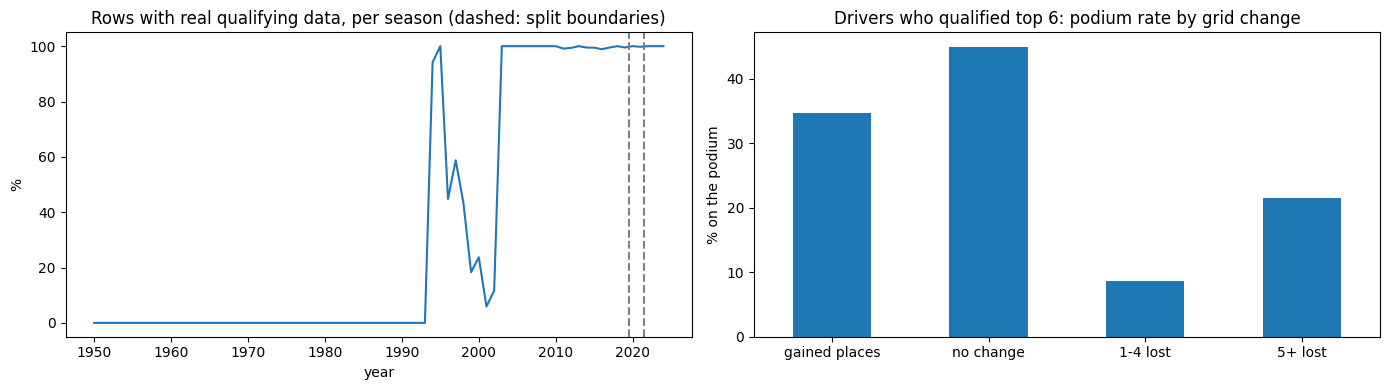

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

(model_table.groupby('year')['has_quali'].mean() * 100).plot(ax=axes[0])
for year in (2019.5, 2021.5):
    axes[0].axvline(year, color='grey', linestyle='--')
axes[0].set_title('Rows with real qualifying data, per season (dashed: split boundaries)')
axes[0].set_ylabel('%')

real = TR[TR['has_quali'] == 1]
print(f'In training rows with real qualifying data, grid differs from qualifying in {(real["grid_penalty"] != 0).mean():.0%} of rows.')
penalty_band = pd.cut(real['grid_penalty'], [-100, -1, 0, 4, 100], labels=['gained places', 'no change', '1-4 lost', '5+ lost'])
top6 = real[real['quali_pos'] <= 6]
(top6.groupby(penalty_band[top6.index], observed=True)[TARGET].mean() * 100).plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Drivers who qualified top 6: podium rate by grid change')
axes[1].set_ylabel('% on the podium')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

The right plot is why we keep both `quali_pos` and `grid_penalty`. Among drivers who qualified in the top 6, those
who start where they qualified podium about 45 % of the time, but only about 9 % after losing 1 to 4 places.
Losing 5 or more places is less harmful (about 21 %), because big drops usually come from engine-part penalties, and
those mostly hit fast cars that can still fight back through the field. Qualifying shows the car's pace; the grid
shows where it actually starts. The model needs both.

**Qualifying gap and the 7 % cap.** A few qualifying times are extreme (one is 900 % slower than pole) because of a wet
session, a lap with an incident, or a data error. These do not describe car pace. F1's own "107 % rule" treats anything
more than 7 % off pole as abnormal, so we cap the gap at 7 %. Without the cap these few values would stretch the scaling
for every other row.

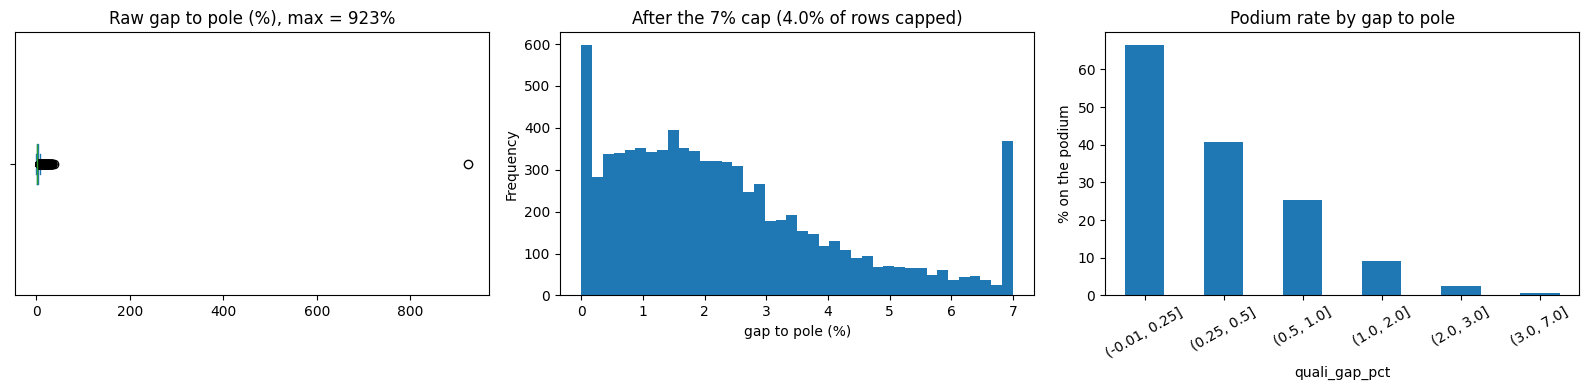

In [27]:
q = clean['qualifying'].merge(clean['races'][['raceId', 'year']], on='raceId')
best_lap = q[['q1', 'q2', 'q3']].min(axis=1)
raw_gap = (best_lap / best_lap.groupby(q['raceId']).transform('min') - 1) * 100
raw_gap = raw_gap[q['year'] <= 2019]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw_gap.plot(kind='box', ax=axes[0], vert=False)
axes[0].set_title(f'Raw gap to pole (%), max = {raw_gap.max():.0f}%')
raw_gap.clip(upper=7).plot(kind='hist', bins=40, ax=axes[1])
axes[1].set_title(f'After the 7% cap ({(raw_gap > 7).mean():.1%} of rows capped)')
axes[1].set_xlabel('gap to pole (%)')
gap_band = pd.cut(TR['quali_gap_pct'], [-0.01, 0.25, 0.5, 1, 2, 3, 7])
(TR.groupby(gap_band, observed=True)[TARGET].mean() * 100).plot(kind='bar', ax=axes[2], rot=30)
axes[2].set_title('Podium rate by gap to pole')
axes[2].set_ylabel('% on the podium')
plt.tight_layout()
plt.show()

**Form and standings.** For each of these features we split the training rows into bins and plot the podium rate per
bin. A feature is useful if the rate changes clearly from bin to bin.

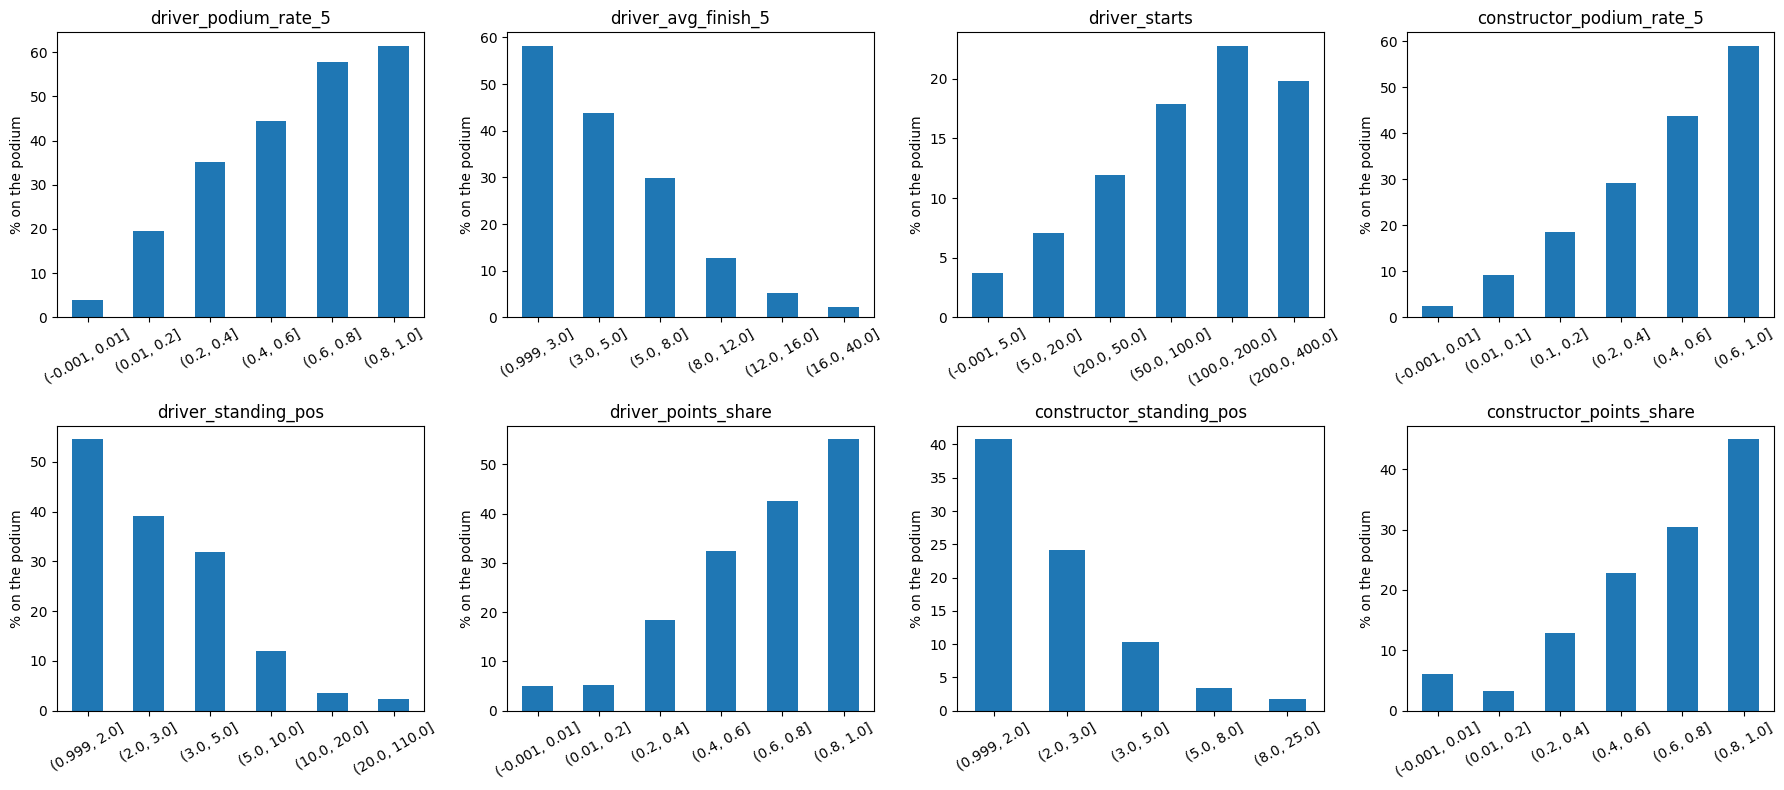

In [28]:
def podium_rate_by_bins(ax, feature, bins):
    band = pd.cut(TR[feature], bins, include_lowest=True)
    (TR.groupby(band, observed=True)[TARGET].mean() * 100).plot(kind='bar', ax=ax, rot=30)
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.set_ylabel('% on the podium')

plots = [
    ('driver_podium_rate_5', [0, 0.01, 0.2, 0.4, 0.6, 0.8, 1]),
    ('driver_avg_finish_5', [1, 3, 5, 8, 12, 16, 40]),
    ('driver_starts', [0, 5, 20, 50, 100, 200, 400]),
    ('constructor_podium_rate_5', [0, 0.01, 0.1, 0.2, 0.4, 0.6, 1]),
    ('driver_standing_pos', [1, 2, 3, 5, 10, 20, 110]),
    ('driver_points_share', [0, 0.01, 0.2, 0.4, 0.6, 0.8, 1]),
    ('constructor_standing_pos', [1, 2, 3, 5, 8, 25]),
    ('constructor_points_share', [0, 0.01, 0.2, 0.4, 0.6, 0.8, 1]),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (feature, bins) in zip(axes.flat, plots):
    podium_rate_by_bins(ax, feature, bins)
plt.tight_layout()
plt.show()

**Correlation with the target.** Spearman correlation (rank based, so it also works for features like `grid_pos`
whose effect is not a straight line) between every feature and `podium`, on the training seasons.

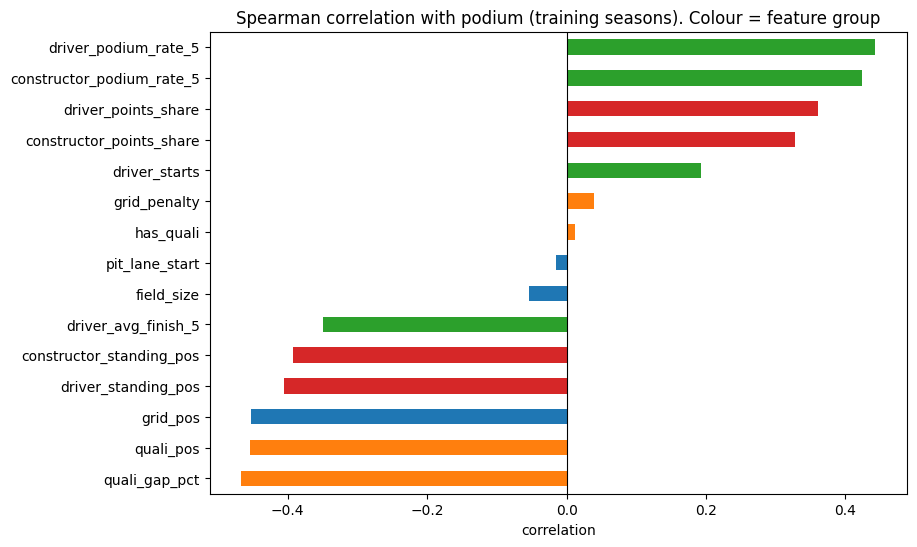

In [29]:
correlation = TR[ALL_FEATURES].corrwith(TR[TARGET], method='spearman').sort_values()
group_of = {f: g for g, features in FEATURE_GROUPS.items() for f in features}
colors = correlation.index.map(lambda f: {'grid': 'C0', 'qualifying': 'C1', 'form': 'C2', 'standings': 'C3'}[group_of[f]])
correlation.plot(kind='barh', color=list(colors), figsize=(9, 6))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Spearman correlation with podium (training seasons). Colour = feature group')
plt.xlabel('correlation')
plt.show()

What the evidence says:
* **Grid and qualifying** have the strongest link: the further back a driver starts, the lower the podium chance.
  `quali_gap_pct` measures pace directly, and on the rows where it exists it is as strong as the position itself.
* **Form and standings** are almost as strong. They capture how good the car and driver are right now, which the
  grid alone does not fully show (a fast car starting 10th after a penalty is still a podium candidate).
* `pit_lane_start`, `has_quali`, `grid_penalty` and `field_size` correlate weakly on their own. We keep them anyway:
  they adjust other features rather than predict alone (for example, `has_quali` tells the model whether `quali_pos`
  is real or a copy of the grid). The ablation in Section 4 measures what each group adds after training.

### 3.6 Encoding, imputation and scaling

**Encoding.** All features are already numbers; yes/no features (`pit_lane_start`, `has_quali`) are stored as 0/1.
We deliberately do **not** one-hot encode `driverId`, `constructorId` or `circuitId`:
* identities do not carry over in time: the test seasons contain drivers who never raced in the training seasons,
  and teams change name (and ID) when they are sold;
* there are about 860 drivers, so one-hot encoding would add hundreds of mostly empty columns that let the model
  memorise who used to be good.

The form and standings features carry the same information ("this driver and this team are fast right now") in a
form that also works for new drivers and renamed teams.

**Imputation.** Missing values come from three places: no qualifying data (`quali_gap_pct`), a driver's or team's first
race (form), and the first race of a season or a driver's first race of the season (standings position). We fill them with the
**median of the training rows**, because the median is not pulled by skewed values like the long tail of `driver_starts`.

**Scaling.** `StandardScaler` (mean 0, standard deviation 1). Logistic regression and the neural network learn
by gradient steps and use a penalty on the weights, so features must be on the same scale. Tree models do not need it.

Both steps sit inside one scikit-learn `Pipeline`, so they are **fitted on the training rows only** and then applied
unchanged to validation, test and new records.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve


def make_preprocessor(impute='median', scale=True):
    steps = [('impute', SimpleImputer(strategy=impute))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps)


missing = pd.DataFrame({name: d[ALL_FEATURES].isna().mean() * 100 for name, d in [('train', TR), ('validation', VA), ('test', TE)]})
missing[missing.sum(axis=1) > 0].round(1).rename(columns=lambda c: f'% missing in {c}')

,% missing in train,% missing in validation,% missing in test
quali_gap_pct,63.7,1.2,1.0
driver_podium_rate_5,3.0,0.8,0.6
driver_avg_finish_5,3.0,0.8,0.6
constructor_podium_rate_5,1.1,0.5,0.1
driver_standing_pos,12.4,5.5,5.0
constructor_standing_pos,12.4,5.2,4.4


The effect of each step on the values, for two features with many missing values:

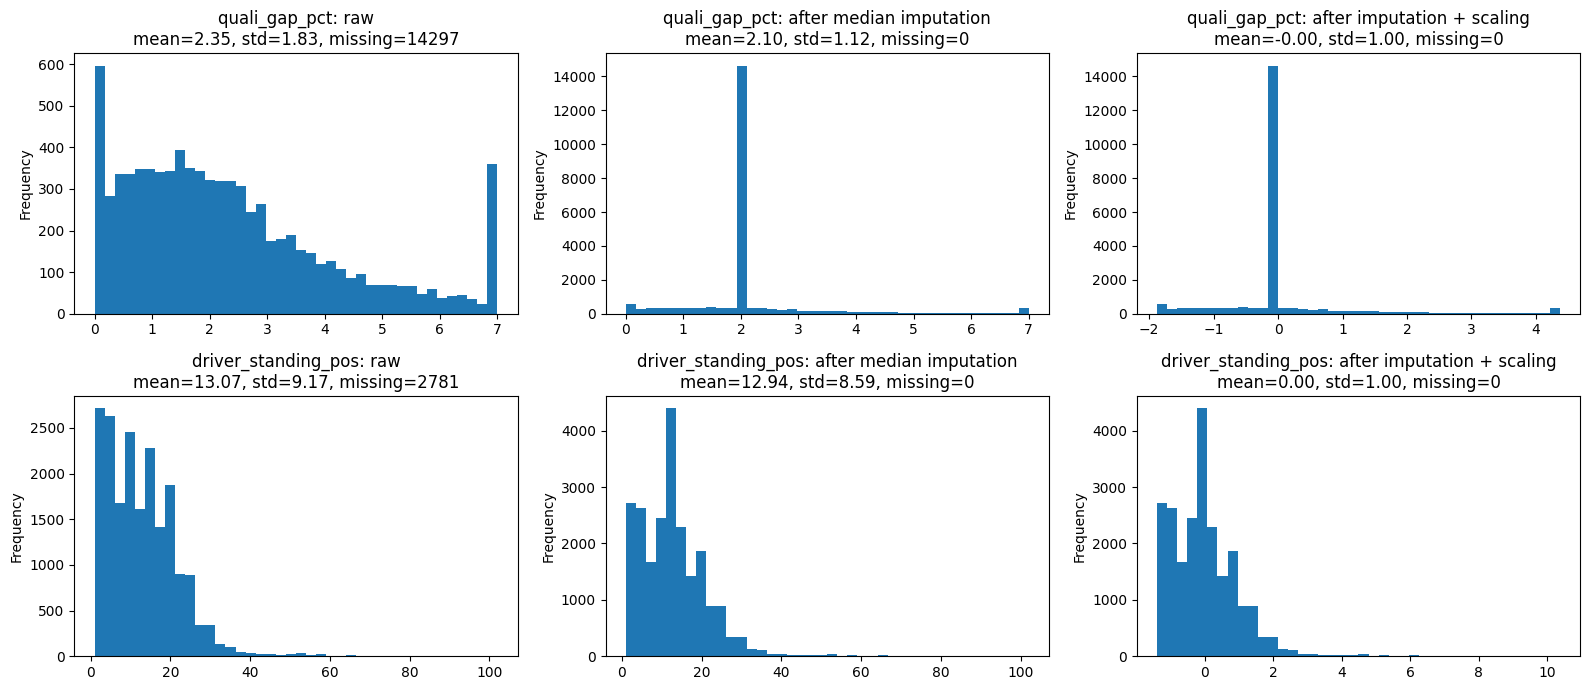

In [31]:
prep = make_preprocessor().fit(TR[ALL_FEATURES])
imputed = pd.DataFrame(prep.named_steps['impute'].transform(TR[ALL_FEATURES]), columns=ALL_FEATURES)
scaled = pd.DataFrame(prep.transform(TR[ALL_FEATURES]), columns=ALL_FEATURES)

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, feature in enumerate(['quali_gap_pct', 'driver_standing_pos']):
    for col, (title, values) in enumerate([('raw', TR[feature]), ('after median imputation', imputed[feature]),
                                           ('after imputation + scaling', scaled[feature])]):
        values.plot(kind='hist', bins=40, ax=axes[row, col])
        axes[row, col].set_title(f'{feature}: {title}\nmean={values.mean():.2f}, std={values.std():.2f}, missing={values.isna().sum()}')
plt.tight_layout()
plt.show()

* Imputation removes the missing values but puts a tall spike at the median: 64 % of the training rows have no
  qualifying gap, and all of them get the same value. `has_quali` tells the model which rows these are.
* The imputed spike also shrinks the standard deviation of `quali_gap_pct` (1.83 to 1.12). Experiment 2 in 3.7 looks at
  what that means for the order of the two steps.
* Scaling only shifts and stretches the axis (mean 0, std 1). The shape of the distribution stays the same.

### 3.7 Preprocessing-order experiments

We test whether the **order** of the preprocessing steps matters. To measure each change we always use the same small
probe model: a logistic regression on all features, trained on the training seasons and scored with **PR-AUC on
validation** (our primary metric; see Section 4). We use logistic regression because it is our baseline and is the
model most sensitive to preprocessing (tree models are not affected by scaling at all).

First, how large a difference is just noise? We resample the validation races 200 times with replacement and look at how
much the PR-AUC of the same predictions moves.

In [32]:
def probe_model(preprocessor):
    return Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=2000))])


def probe(train, valid, preprocessor, features=ALL_FEATURES):
    model = probe_model(preprocessor).fit(train[features], train[TARGET])
    return average_precision_score(valid[TARGET], model.predict_proba(valid[features])[:, 1])


base_model = probe_model(make_preprocessor()).fit(TR[ALL_FEATURES], TR[TARGET])
va_scored = VA[['raceId', TARGET]].assign(prob=base_model.predict_proba(VA[ALL_FEATURES])[:, 1])
baseline_score = average_precision_score(va_scored[TARGET], va_scored['prob'])

# bootstrap over whole races, because the rows of one race belong together
by_race = [group for _, group in va_scored.groupby('raceId')]
boot_rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    sample = pd.concat([by_race[i] for i in boot_rng.integers(0, len(by_race), len(by_race))])
    boot.append(average_precision_score(sample[TARGET], sample['prob']))
noise = np.std(boot)

prep_results = {'baseline: impute (median) -> scale, fitted on train only': baseline_score}
print(f'Baseline validation PR-AUC: {baseline_score:.4f}')
print(f'Bootstrap standard deviation: {noise:.4f}. Differences smaller than this are noise.')

Baseline validation PR-AUC: 0.7157
Bootstrap standard deviation: 0.0560. Differences smaller than this are noise.


**Experiment 1: fit the preprocessing before or after the split?**
A common mistake is to fit the imputer and scaler on the whole table and split afterwards. Then the medians, means and
standard deviations also come from the validation and test seasons, which is information from the future.

In [33]:
leaky = make_preprocessor().fit(model_table[ALL_FEATURES])          # fitted on ALL seasons
X_tr, X_va = leaky.transform(TR[ALL_FEATURES]), leaky.transform(VA[ALL_FEATURES])
leaky_prob = LogisticRegression(max_iter=2000).fit(X_tr, TR[TARGET]).predict_proba(X_va)[:, 1]
prep_results['exp 1: imputer and scaler fitted on all seasons (leaky)'] = average_precision_score(VA[TARGET], leaky_prob)

train_only = make_preprocessor().fit(TR[ALL_FEATURES])
print(pd.DataFrame({
    'median fitted on train': train_only.named_steps['impute'].statistics_,
    'median fitted on all seasons': leaky.named_steps['impute'].statistics_,
}, index=ALL_FEATURES).loc[['quali_gap_pct', 'driver_starts', 'driver_standing_pos']])
print(f"\nValidation PR-AUC, fitted on train only: {prep_results['baseline: impute (median) -> scale, fitted on train only']:.4f}")
print(f"Validation PR-AUC, fitted on all seasons: {prep_results['exp 1: imputer and scaler fitted on all seasons (leaky)']:.4f}")

                     median fitted on train  median fitted on all seasons
quali_gap_pct                      1.961169                      1.835955
driver_starts                     41.000000                     45.000000
driver_standing_pos               12.000000                     12.000000

Validation PR-AUC, fitted on train only: 0.7157
Validation PR-AUC, fitted on all seasons: 0.7160


**Experiment 2: impute then scale, or scale then impute?**
If we impute first, the scaler's mean and standard deviation are computed over real values *plus* thousands of copies
of the median, so the standard deviation shrinks. If we scale first, they are computed over the real values only.

In [34]:
scale_first = Pipeline([('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median'))])
prep_results['exp 2: scale -> impute'] = probe(TR, VA, scale_first)

impute_first = make_preprocessor().fit(TR[ALL_FEATURES])
scale_first.fit(TR[ALL_FEATURES])
i = ALL_FEATURES.index('quali_gap_pct')
print('quali_gap_pct, standard deviation used by the scaler:')
print(f'  impute -> scale: {impute_first.named_steps["scale"].scale_[i]:.3f}')
print(f'  scale -> impute: {scale_first.named_steps["scale"].scale_[i]:.3f}')
print(f"\nValidation PR-AUC, impute -> scale: {baseline_score:.4f}")
print(f"Validation PR-AUC, scale -> impute: {prep_results['exp 2: scale -> impute']:.4f}")

quali_gap_pct, standard deviation used by the scaler:
  impute -> scale: 1.120
  scale -> impute: 1.832

Validation PR-AUC, impute -> scale: 0.7157
Validation PR-AUC, scale -> impute: 0.7161


**Experiment 3: grid fallback before imputation, or imputation only?**
Our pipeline first fills a missing qualifying position with the grid position (a domain rule), and only then lets the
imputer fill what is left. The alternative is to leave `quali_pos` missing and let the imputer put the median
qualifying position (about 11th) everywhere, even for a driver starting on pole.

In [35]:
def without_fallback(d):
    d = d.copy()
    d['quali_pos'] = d['quali_raw']                    # no fallback: missing stays missing
    d['grid_penalty'] = d['grid_pos'] - d['quali_raw']
    return d

prep_results['exp 3: no grid fallback, median imputation only'] = probe(without_fallback(TR), without_fallback(VA), make_preprocessor())

no_fb = without_fallback(TR)
filled = make_preprocessor(scale=False).fit(no_fb[ALL_FEATURES]).transform(no_fb[ALL_FEATURES])[:, ALL_FEATURES.index('quali_pos')]
pole_no_quali = (TR['grid_pos'] == 1) & (TR['has_quali'] == 0)
print(f'Pole sitters without qualifying data in training: {pole_no_quali.sum()}')
print(f'  their quali_pos with the fallback: {TR.loc[pole_no_quali, "quali_pos"].mean():.0f}')
print(f'  their quali_pos with median imputation only: {filled[pole_no_quali.values].mean():.0f}')
print(f"\nValidation PR-AUC, with fallback: {baseline_score:.4f}")
print(f"Validation PR-AUC, imputation only: {prep_results['exp 3: no grid fallback, median imputation only']:.4f}")

Pole sitters without qualifying data in training: 619
  their quali_pos with the fallback: 1
  their quali_pos with median imputation only: 11

Validation PR-AUC, with fallback: 0.7157
Validation PR-AUC, imputation only: 0.7189


**Experiment 4: how far back should the training data go?**
Older seasons have bigger fields, worse reliability and no qualifying data. We try starting the training data in
different years (the validation seasons stay the same).

In [36]:
window = {}
for start in [1950, 1970, 1981, 1994, 2003]:
    window[start] = probe(TR[TR['year'] >= start], VA, make_preprocessor())
    prep_results[f'exp 4: train from {start}'] = window[start]
print(pd.DataFrame({'training rows': [int((TR['year'] >= s).sum()) for s in window],
                    'validation PR-AUC': [round(v, 4) for v in window.values()]}, index=list(window)))

      training rows  validation PR-AUC
1950          22459             0.7157
1970          19105             0.7203
1981          15339             0.7149
1994          10093             0.7151
2003           6783             0.7187


In [37]:
results_table = pd.DataFrame({'validation PR-AUC': prep_results}).round(4)
results_table['difference vs baseline'] = (results_table['validation PR-AUC'] - baseline_score).round(4)
results_table['bigger than noise?'] = results_table['difference vs baseline'].abs() > noise
results_table

,validation PR-AUC,difference vs baseline,bigger than noise?
"baseline: impute (median) -> scale, fitted on train only",0.7157,0.0000,False
exp 1: imputer and scaler fitted on all seasons (leaky),0.7160,0.0003,False
exp 2: scale -> impute,0.7161,0.0004,False
"exp 3: no grid fallback, median imputation only",0.7189,0.0032,False
exp 4: train from 1950,0.7157,0.0000,False
exp 4: train from 1970,0.7203,0.0046,False
exp 4: train from 1981,0.7149,-0.0008,False
exp 4: train from 1994,0.7151,-0.0006,False
exp 4: train from 2003,0.7187,0.0030,False


**Decisions from the experiments**

With this probe model, every variant lands within the noise level of the baseline. The choices did not change the
validation score in a measurable way, so we decide by which choice is *correct*, not by the score:

1. **Fit the preprocessing on the training seasons only (inside the Pipeline).** The leaky version used medians and means
   from 2020–2024, which do not exist at prediction time. It happened not to change the score here, but it is wrong and
   could change scores with another model. Keeping everything in a `Pipeline` makes it impossible to get wrong.
2. **Impute, then scale.** The scores are the same. Imputing first means the scaler sees exactly the values the model
   will see, so the scaled features really have mean 0 and standard deviation 1.
3. **Keep the grid fallback.** The scores are the same, because the validation seasons have complete qualifying data,
   so the fallback only changes training rows. The fallback still gives realistic values: a pole sitter gets
   `quali_pos = 1`, not the median of 11. That matters for any record with missing qualifying (see the inference function in 3.9).
4. **Train on all seasons from 1950.** The start year makes no measurable difference, so we keep the most data. The
   features (`has_quali`, `field_size`, points share) already account for the differences between eras.

Section 4 can repeat experiments 1 and 3 with the tree and neural-network models, where the effect may be larger.

### 3.8 Freeze the modeling table

The table is saved to `model_table.csv`, and a fingerprint (a hash of every value) is printed. If anyone changes the
table, the fingerprint changes, so Section 4 can check it is working on the same rows and features.

**Objects for Section 4:** `model_table`, `TR`, `VA`, `TE`, `TARGET`, `FEATURE_GROUPS`, `ALL_FEATURES`,
`make_preprocessor()`, `build_model_table()`, and `predict_podium()` (3.9).

In [38]:
model_table.to_csv('model_table.csv', index=False)
fingerprint = pd.util.hash_pandas_object(model_table[['raceId', 'driverId'] + ALL_FEATURES + [TARGET]], index=False).sum()
print(f'Saved model_table.csv: {model_table.shape[0]} rows, {len(ALL_FEATURES)} features')
print(f'Fingerprint: {fingerprint}')
print('Feature groups:', {g: len(f) for g, f in FEATURE_GROUPS.items()})

Saved model_table.csv: 24586 rows, 15 features
Fingerprint: 17859401350359469056
Feature groups: {'grid': 3, 'qualifying': 4, 'form': 4, 'standings': 4}


### 3.9 Inference function

`predict_podium(record, model, threshold)` takes one driver's pre-race information as a dictionary and returns the
podium probability and a yes/no prediction.

* The record uses the **raw** inputs: `grid`, `field_size`, `quali_position`, `quali_gap_pct`, plus the form and
  standings values. It goes through the same `add_grid_quali_features` function as the table, so pit-lane starts,
  the qualifying fallback and the 7 % cap are handled exactly like in training.
* **Any input can be missing.** Missing qualifying falls back to the grid; anything else missing is filled by the
  imputer inside the model's pipeline, with medians learned from the training seasons.
* `model` is any fitted pipeline that takes `ALL_FEATURES`. Here we use the logistic-regression baseline from 3.7.
  Section 4 can pass the final model instead.

The threshold is the one that gives the best F1 on the **validation** seasons.

In [39]:
RECORD_INPUTS = ['grid', 'field_size', 'quali_position', 'quali_gap_pct',
                 'driver_podium_rate_5', 'driver_avg_finish_5', 'driver_starts', 'constructor_podium_rate_5',
                 'driver_standing_pos', 'driver_points_share', 'constructor_standing_pos', 'constructor_points_share']


def predict_podium(record, model, threshold=0.5):
    unknown = set(record) - set(RECORD_INPUTS)
    assert not unknown, f'unknown inputs: {unknown}'
    row = pd.DataFrame([{k: record.get(k, np.nan) for k in RECORD_INPUTS}], dtype=float)
    row = add_grid_quali_features(row.rename(columns={'quali_position': 'quali_raw'}))
    probability = model.predict_proba(row[ALL_FEATURES])[0, 1]
    return {'podium_probability': round(float(probability), 3),
            'podium': bool(probability >= threshold),
            'missing_inputs': [k for k in RECORD_INPUTS if pd.isna(record.get(k, np.nan))]}


# threshold with the best F1 on validation
precision, recall, thresholds = precision_recall_curve(VA[TARGET], base_model.predict_proba(VA[ALL_FEATURES])[:, 1])
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-9, None)
best_threshold = float(thresholds[np.argmax(f1[:-1])])
print(f'Threshold chosen on validation: {best_threshold:.3f} (F1 = {f1[:-1].max():.3f})')

Threshold chosen on validation: 0.246 (F1 = 0.712)


**Demo.** We take a real row from the test seasons (a race in the middle of a season, so standings exist) and write it
as a record. First we check that the function gives exactly the same probability as the model applied directly to that
row of the table. The partial record is the same driver with the qualifying and standings inputs removed, as if that
data was not available.

In [40]:
example = TE[(TE['round'] >= 5) & (TE['quali_pos'] == 3) & (TE['grid_pos'] == 3)].iloc[0]
complete = {
    'grid': example['grid_pos'], 'field_size': example['field_size'],
    'quali_position': example['quali_pos'], 'quali_gap_pct': example['quali_gap_pct'],
    **{f: example[f] for f in FEATURE_GROUPS['form'] + FEATURE_GROUPS['standings']},
}
partial = {k: v for k, v in complete.items() if k not in
           ['quali_position', 'quali_gap_pct', 'driver_standing_pos', 'constructor_standing_pos']}

from_table = base_model.predict_proba(TE.loc[[example.name], ALL_FEATURES])[0, 1]
assert abs(predict_podium(complete, base_model)['podium_probability'] - from_table) < 1e-3

print(f"Race: {example['name']} {example['year']}, driverId {example['driverId']}, "
      f"actual result: {'podium' if example[TARGET] else 'no podium'}")
print(f'Probability from the table row: {from_table:.3f}\n')
demo = pd.DataFrame({'complete record': pd.Series(complete, dtype=object),
                     'partial record': pd.Series(partial, dtype=object).reindex(list(complete))})
for name, record in [('complete record', complete), ('partial record', partial)]:
    for key, value in predict_podium(record, base_model, best_threshold).items():
        demo.loc[key, name] = value if key != 'missing_inputs' else ', '.join(value) or '-'
demo

Race: Miami Grand Prix 2022, driverId 830, actual result: podium
Probability from the table row: 0.580



,complete record,partial record
grid,3,3
field_size,20,20
quali_position,3.0,NaN
quali_gap_pct,0.219604,NaN
driver_podium_rate_5,0.6,0.6
driver_avg_finish_5,8.0,8.0
driver_starts,145,145
constructor_podium_rate_5,0.5,0.5
driver_standing_pos,2.0,NaN
driver_points_share,0.686047,0.686047


Both records get a prediction. For the partial record, `quali_pos` is taken from the grid (the fallback) and
`has_quali` becomes 0; the gap to pole and the two standings positions are filled with the training medians. The
probability moves a little because the model has less information about this driver, but the function does not crash
and the result stays sensible.